In [1]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad=0

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        return Value(self.data + other.data, (self, other), '+')

    def __mul__(self, other):
        return Value(self.data * other.data, (self, other), '*')

In [14]:
# Visualizing the expression graph
from graphviz import Digraph

In [15]:
from graphviz import Digraph

def trace(root):
    """Walk backwards from root, collecting every node and edge."""
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # left to right
    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))
        # a box showing the label and the value
        dot.node(name=uid, label="{ %s | data %.4f }" % (n.label, n.data), shape='record')
        if n._op:
            # a small extra node for the operation (+ or *)
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect the child to the operation node of its parent
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')

e = a * b;  e.label = 'e'
d = e + c;  d.label = 'd'
f=Value(-2.0, label='f')
L=d*f; L.label='L'

dot = draw_dot(d)
# dot.render('graph', view=True)   # writes graph.svg and opens it
# In Jupyter, just end the cell with:  draw_dot(d)
L

Value(data=-8.0)

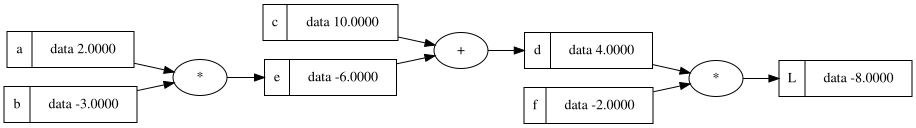

In [16]:
draw_dot(L)